In [4]:
from sklearn.datasets import make_regression
from LinearRegression import LinearRegression
from MyPolynomialRegression import MyPolynomialRegression
from sklearn.linear_model import LinearRegression as SklearnLR
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
X, y = make_regression(n_samples=1000, n_features=1, noise=10, random_state=42)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
sklearn_lr = SklearnLR()
sklearn_lr.fit(X_train, y_train)
sklearn_pred = sklearn_lr.predict(X_test)
print("Sklearn R²:", r2_score(y_test, sklearn_pred))

Sklearn R²: 0.7188122876167204


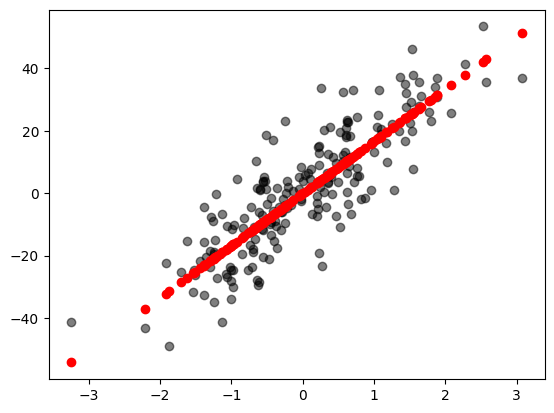

In [29]:
plt.scatter(X_test, y_test, color='black', alpha=0.5)
plt.scatter(X_test, sklearn_pred, color='red') 
plt.show()

In [22]:
my_lr = LinearRegression(lr=0.01, n_iters=2000)
my_lr.fit(X_train, y_train)
my_pred = my_lr.predict(X_test)

print("my R²:", r2_score(y_test, my_pred))

my R²: 0.7188122879135014


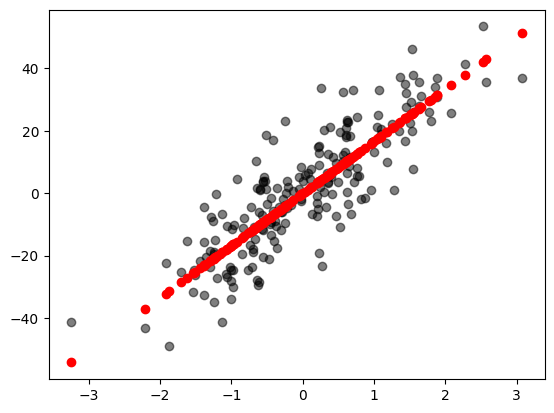

In [30]:
plt.scatter(X_test, y_test, color='black', alpha=0.5)
plt.scatter(X_test, my_pred, color='red') 
plt.show()

In [ ]:
X = np.random.uniform(-3, 3, 200).reshape(-1,1)
y = (X**2).flatten() + np.random.normal(0, 1, 200)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

Sklearn Poly R²: 0.8867491562373184


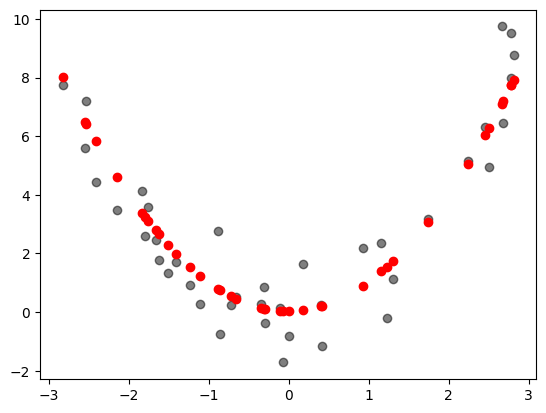

In [ ]:
poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

sklearn_poly = LinearRegression()
sklearn_poly.fit(X_train_poly, y_train)

poly_pred = sklearn_poly.predict(X_test_poly)

print("Sklearn Poly R²:", r2_score(y_test, poly_pred))

plt.scatter(X_test, y_test, color='black', alpha=0.5)
plt.scatter(X_test, poly_pred, color='red')
plt.show()

In [13]:
my_poly_normal = MyPolynomialRegression(degree=3)
my_poly_normal.fit(X_train, y_train, method="normal")
pred_normal = my_poly_normal.predict(X_test)
print("Normal equation R²:", r2_score(y_test, pred_normal))

my_poly_gd = MyPolynomialRegression(degree=3, lr=0.01, n_iters=5000)
my_poly_gd.fit(X_train, y_train, method="gd")
pred_gd = my_poly_gd.predict(X_test)
print("Gradient descent R²:", r2_score(y_test, pred_gd))

Normal equation R²: 0.8867515648325944
Gradient descent R²: 0.8867515648318088


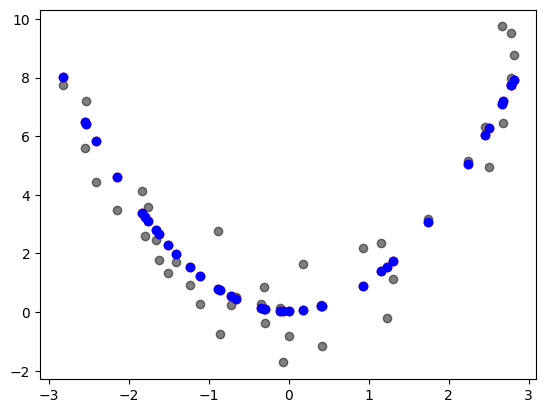

In [15]:
plt.scatter(X_test, y_test, color='black', alpha=0.5)
plt.scatter(X_test, pred_normal, color='red')
plt.scatter(X_test, pred_gd, color='blue')
plt.show()